# 02 — ACM et rapprochement de modalités

Les règles de recodification et d’exclusion sont identiques à celles du notebook fourni. La condition de contribution sur les cinq premiers axes est conservée.

In [1]:
from pathlib import Path
import sys

RACINE = Path.cwd().resolve()
if RACINE.name == 'notebooks':
    RACINE = RACINE.parent
sys.path.insert(0, str(RACINE))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import yaml
from src.preparation import preparer_donnees, charger_regroupements, decrire_distributions
from src.acm import executer_iteration_1, executer_iteration_2
from src.proximite_modalites import comparer_modalites


In [2]:
donnees_brutes = pd.read_csv(RACINE / 'data/brutes/td_clustering_karafun.csv')
regroupements = charger_regroupements(RACINE / 'config/regroupements.yaml')
donnees_preparees, donnees_nettoyees = preparer_donnees(donnees_brutes, regroupements)
for variable, tableau in decrire_distributions(donnees_preparees).items():
    print(f'\n=== {variable} ===')
    display(tableau)



=== anciennete_client_rec ===


,Fréquence,Pourcentage (%)
anciennete_client_rec,,
02_6_a_12_mois,98460,28.87
01_Moins_de_6_mois,67839,19.89
04_2_a_4_ans,63540,18.63
03_1_a_2_ans,62930,18.45
05_Plus_de_4_ans,48322,14.17



=== anciennete_abonnement_rec ===


,Fréquence,Pourcentage (%)
anciennete_abonnement_rec,,
03_6_a_12_mois,131873,38.66
01_Moins_de_3_mois,69795,20.46
02_3_a_5_mois,52697,15.45
04_1_a_2_ans,45378,13.30
05_Plus_de_2_ans,41348,12.12



=== methode_paiement_rec ===


,Fréquence,Pourcentage (%)
methode_paiement_rec,,
web_et_direct,172829,50.67
telephone,164814,48.32
Amazon,2846,0.83
Credit,602,0.18


... (4 outputs left out)


=== avg_songs_sessions_rec ===


,Fréquence,Pourcentage (%)
avg_songs_sessions_rec,,
01_Faible_1_a_5,97035,28.45
02_Moyen_5_a_10,80920,23.72
03_Eleve_10_a_20,76782,22.51
04_Tres_eleve_20_et_plus,45639,13.38
00_Inactif,40715,11.94



=== zone_geo_rec ===


,Fréquence,Pourcentage (%)
zone_geo_rec,,
02_Europe,155980,45.73
01_US,140841,41.29
03_CA,23999,7.04
04_Reste_du_Monde,20271,5.94


## Itération 1 — Toutes les variables actives

Itération 1 : 68218 individus, 11 variables
Nombre de modalités actives (K) : 47
Nombre d'axes factoriels calculés : 36

=== Inertie expliquée par les axes factoriels (p = 11 variables, 1/p = 0.091) ===
   Axe  Valeur Propre λ > 1/p  Inertie Brute (%)  Inertie Brute Cumulée (%)  Inertie Benzécri (%)  Inertie Benzécri Cumulée (%)
 Axe 1           0.30     oui               9.29                       9.29                 51.67                         51.67
 Axe 2           0.23     oui               7.16                      16.45                 23.42                         75.09
 Axe 3           0.19     oui               5.85                      22.30                 11.54                         86.63
 Axe 4           0.16     oui               4.88                      27.18                  5.37                         92.01
 Axe 5           0.15     oui               4.54                      31.71                  3.78                         95.79
 Axe 6           0.13     oui

,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 1,Contrib Axe 1 (%)
type_client__churn,type_client,churn,34314,50.3,-0.506,3.86
type_client__nouveau,type_client,nouveau,10980,16.1,-0.522,1.31
type_client__reactivated,type_client,reactivated,9932,14.6,0.085,0.03
type_client__retained,type_client,retained,12992,19.0,1.714,16.73
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.756,4.67
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.356,0.44
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.104,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.666,1.25
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.662,4.76
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,-1.193,1.53



--- Axe 2 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 2,Contrib Axe 2 (%)
type_client__churn,type_client,churn,34314,50.3,-0.635,7.87
type_client__nouveau,type_client,nouveau,10980,16.1,1.468,13.46
type_client__reactivated,type_client,reactivated,9932,14.6,0.402,0.91
type_client__retained,type_client,retained,12992,19.0,0.129,0.12
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.783,6.50
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.413,0.76
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.190,0.17
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.254,0.24
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.619,5.40
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,2.332,7.56



--- Axe 3 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 3,Contrib Axe 3 (%)
type_client__churn,type_client,churn,34314,50.3,-0.035,0.03
type_client__nouveau,type_client,nouveau,10980,16.1,0.665,3.38
type_client__reactivated,type_client,reactivated,9932,14.6,-0.536,1.98
type_client__retained,type_client,retained,12992,19.0,-0.061,0.03
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.339,1.49
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.031,0.01
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,0.105,0.06
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.216,0.21
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.094,0.15
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,1.953,6.48


... (4 outputs left out)


=== Diagnostic par variable ===


,Nb modalités,Nb modalités > seuil,Contrib max (%),Max Axe 1 (%),Max Axe 2 (%),Max Axe 3 (%),Max Axe 4 (%),Max Axe 5 (%),Statut
Variable,,,,,,,,,
zone_geo_rec,4,0,0.56,0.56,0.09,0.21,0.39,0.22,À RETIRER ?
utilise_remote,2,1,2.58,0.21,1.14,2.58,0.51,1.92,OK
methode_paiement_rec,4,2,4.37,0.56,0.01,0.22,1.01,4.37,OK
ratio_fidelite_tr,6,6,7.56,4.76,7.56,6.48,6.66,5.90,OK
contactable,2,2,7.92,0.71,1.03,0.23,1.80,7.92,OK
valeur_12M_rec,5,5,9.36,7.57,0.88,0.73,9.36,4.14,OK
anciennete_abonnement_rec,5,5,10.65,10.65,8.50,4.88,7.98,5.08,OK
anciennete_client_rec,5,5,10.85,3.49,10.85,8.53,9.98,7.11,OK
type_client,4,4,16.73,16.73,13.46,3.38,7.81,5.99,OK


Variables à examiner pour la prochaine itération : ['zone_geo_rec']
variables_a_retirer à copier = ['zone_geo_rec']

=== Modalités proches (distance sur 5 axes, seuil = 0.2) ===
0 paire(s) proche(s) sur 85 paires comparées


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Proches ?
0,zone_geo_rec,02_Europe,04_Reste_du_Monde,31107,4128,0.217,
1,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.275,
2,zone_geo_rec,02_Europe,03_CA,31107,4791,0.358,
3,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.398,
4,avg_songs_sessions_rec,02_Moyen_5_a_10,03_Eleve_10_a_20,16299,15337,0.403,
5,zone_geo_rec,01_US,04_Reste_du_Monde,28192,4128,0.430,
6,avg_songs_sessions_rec,01_Faible_1_a_5,02_Moyen_5_a_10,19480,16299,0.439,
7,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.445,
8,zone_geo_rec,03_CA,04_Reste_du_Monde,4791,4128,0.506,
9,zone_geo_rec,01_US,02_Europe,28192,31107,0.507,


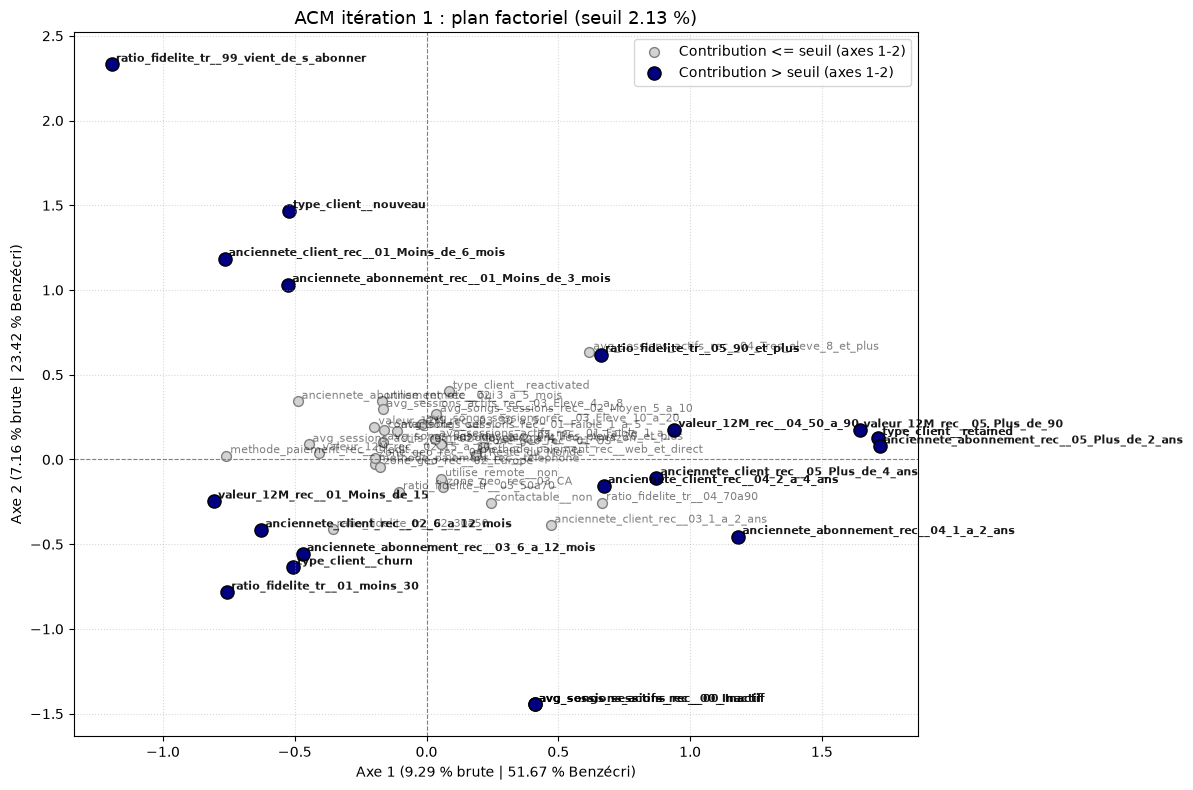

In [3]:
resultats_iteration_1 = executer_iteration_1(donnees_nettoyees, variables_a_retirer=[])


## Itération 2 — Retrait de `zone_geo_rec`

Itération 2 : 68218 individus, 10 variables
Nombre de modalités actives (K) : 43
Nombre d'axes factoriels calculés : 33

=== Inertie expliquée par les axes factoriels (p = 10 variables, 1/p = 0.100) ===
   Axe  Valeur Propre λ > 1/p  Inertie Brute (%)  Inertie Brute Cumulée (%)  Inertie Benzécri (%)  Inertie Benzécri Cumulée (%)
 Axe 1           0.33     oui              10.06                      10.06                 51.56                         51.56
 Axe 2           0.26     oui               7.80                      17.86                 23.78                         75.34
 Axe 3           0.21     oui               6.37                      24.23                 11.65                         86.99
 Axe 4           0.18     oui               5.30                      29.53                  5.40                         92.39
 Axe 5           0.16     oui               4.94                      34.48                  3.83                         96.22
 Axe 6           0.14     oui

,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 1,Contrib Axe 1 (%)
type_client__churn,type_client,churn,34314,50.3,-0.501,3.81
type_client__nouveau,type_client,nouveau,10980,16.1,-0.541,1.42
type_client__reactivated,type_client,reactivated,9932,14.6,0.081,0.03
type_client__retained,type_client,retained,12992,19.0,1.719,16.97
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.745,4.57
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.358,0.45
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.111,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.667,1.26
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.658,4.74
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,-1.215,1.59



--- Axe 2 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 2,Contrib Axe 2 (%)
type_client__churn,type_client,churn,34314,50.3,-0.639,7.97
type_client__nouveau,type_client,nouveau,10980,16.1,1.457,13.28
type_client__reactivated,type_client,reactivated,9932,14.6,0.404,0.92
type_client__retained,type_client,retained,12992,19.0,0.146,0.16
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.784,6.52
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.417,0.78
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.196,0.18
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.250,0.23
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.624,5.48
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,2.314,7.45



--- Axe 3 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 3,Contrib Axe 3 (%)
type_client__churn,type_client,churn,34314,50.3,-0.043,0.04
type_client__nouveau,type_client,nouveau,10980,16.1,0.671,3.45
type_client__reactivated,type_client,reactivated,9932,14.6,-0.541,2.03
type_client__retained,type_client,retained,12992,19.0,-0.041,0.01
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.342,1.52
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.045,0.01
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,0.089,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.222,0.22
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.104,0.19
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,1.990,6.75


... (4 outputs left out)


=== Diagnostic par variable ===


,Nb modalités,Nb modalités > seuil,Contrib max (%),Max Axe 1 (%),Max Axe 2 (%),Max Axe 3 (%),Max Axe 4 (%),Max Axe 5 (%),Statut
Variable,,,,,,,,,
utilise_remote,2,1,2.56,0.22,1.16,2.56,0.53,1.87,OK
methode_paiement_rec,4,2,4.34,0.61,0.02,0.17,0.85,4.34,OK
ratio_fidelite_tr,6,6,7.45,4.74,7.45,6.75,6.73,5.96,OK
contactable,2,2,8.06,0.76,0.98,0.19,1.62,8.06,OK
valeur_12M_rec,5,5,9.07,7.27,0.91,0.76,9.07,4.29,OK
anciennete_client_rec,5,5,10.64,3.65,10.64,8.71,10.48,7.31,OK
anciennete_abonnement_rec,5,5,10.79,10.79,8.40,5.10,7.99,5.00,OK
type_client,4,4,16.97,16.97,13.28,3.45,8.07,5.85,OK
avg_sessions_actifs_rec,5,2,23.46,1.31,9.87,23.46,2.64,0.70,OK


Variables à examiner pour la prochaine itération : aucune
variables_a_retirer à copier = ['zone_geo_rec']

=== Modalités proches (distance sur 5 axes, seuil = 0.2) ===
0 paire(s) proche(s) sur 79 paires comparées


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Proches ?
0,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.279,
1,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.401,
2,avg_songs_sessions_rec,02_Moyen_5_a_10,03_Eleve_10_a_20,16299,15337,0.401,
3,avg_songs_sessions_rec,01_Faible_1_a_5,02_Moyen_5_a_10,19480,16299,0.434,
4,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.443,
5,methode_paiement_rec,Amazon,telephone,543,32926,0.644,
6,anciennete_client_rec,04_2_a_4_ans,05_Plus_de_4_ans,12626,9586,0.653,
7,avg_songs_sessions_rec,02_Moyen_5_a_10,04_Tres_eleve_20_et_plus,16299,8962,0.656,
8,avg_songs_sessions_rec,01_Faible_1_a_5,03_Eleve_10_a_20,19480,15337,0.788,
9,avg_sessions_actifs_rec,01_Faible_1_a_2,03_Eleve_4_a_8,28866,9497,0.800,


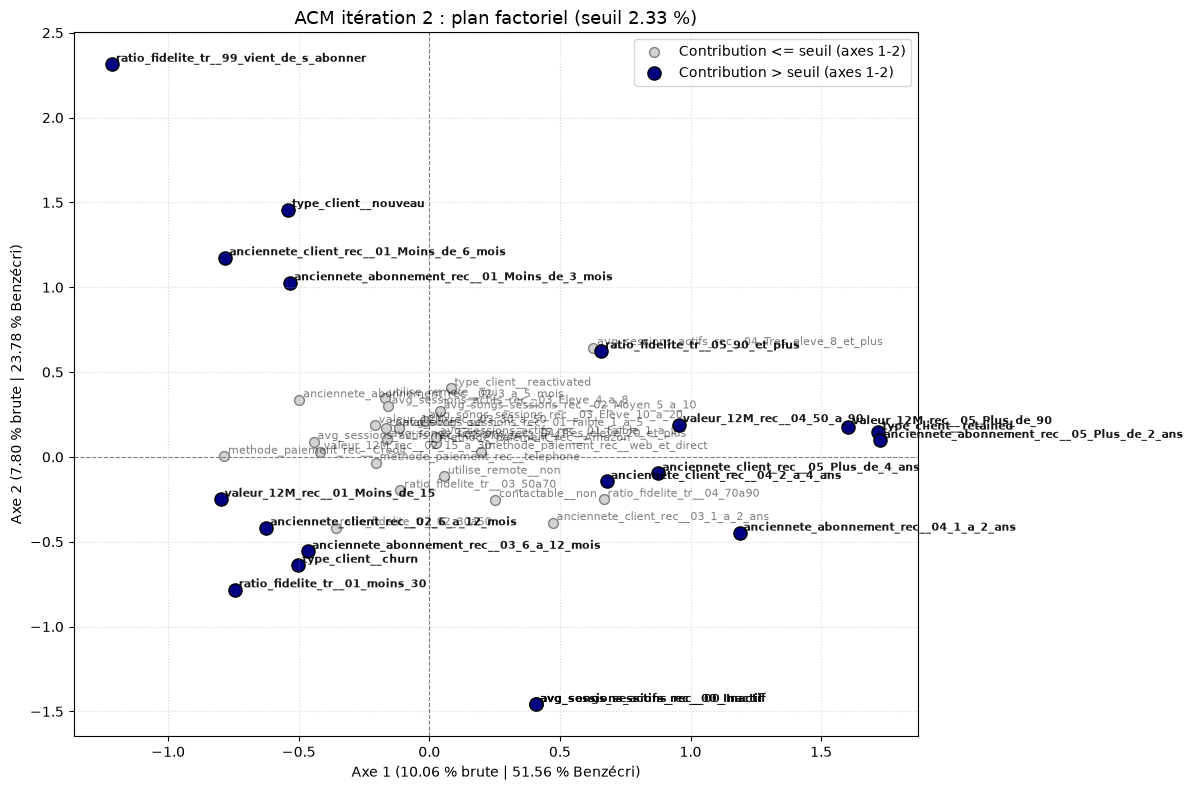

In [4]:
resultats_iteration_2 = executer_iteration_2(donnees_nettoyees, variables_a_retirer=['zone_geo_rec'])


## Comparaison des modalités (distance factorielle et Jensen-Shannon)

In [5]:
comparaison_modalites = comparer_modalites(
    resultats_iteration_2['echantillon_acm'],
    resultats_iteration_2['tableau_modalites'],
    n_axes_proximite=5,
)
comparaison_modalites.to_csv(RACINE / 'resultats/comparaison_modalites.csv', index=False)


Paires les mieux classées selon les deux distances (à examiner) :


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance factorielle,JS moyenne,JS maximale,Rang relatif factoriel,Rang relatif JS,Priorite exploratoire
0,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.4426,0.0707,0.2168,0.0667,0.0667,0.0667
1,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.4014,0.0578,0.1073,0.1000,0.1000,0.1000
2,anciennete_client_rec,04_2_a_4_ans,05_Plus_de_4_ans,12626,9586,0.6534,0.0805,0.1946,0.1000,0.1000,0.1000
3,valeur_12M_rec,02_15_a_30,03_30_a_50,9985,9194,0.8468,0.1130,0.3074,0.1000,0.1000,0.1000
4,anciennete_abonnement_rec,01_Moins_de_3_mois,02_3_a_5_mois,14019,10578,0.9406,0.1151,0.3410,0.1000,0.1000,0.1000
5,ratio_fidelite_tr,03_50a70,04_70a90,8087,6417,0.9031,0.1402,0.3818,0.1333,0.1333,0.1333
6,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.2790,0.0625,0.1266,0.1000,0.2000,0.1500
7,avg_songs_sessions_rec,02_Moyen_5_a_10,03_Eleve_10_a_20,16299,15337,0.4014,0.0470,0.1035,0.2000,0.1000,0.1500
8,type_client,churn,reactivated,34314,9932,1.8028,0.2435,0.5022,0.1667,0.1667,0.1667
9,avg_sessions_actifs_rec,01_Faible_1_a_2,03_Eleve_4_a_8,28866,9497,0.8003,0.0880,0.1862,0.2000,0.2000,0.2000


Paire la plus proche dans l’espace factoriel pour chaque variable :


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance factorielle,JS moyenne,JS maximale,Rang relatif factoriel,Rang relatif JS,Priorite exploratoire
4,anciennete_abonnement_rec,01_Moins_de_3_mois,02_3_a_5_mois,14019,10578,0.9406,0.1151,0.3410,0.1000,0.1000,0.1000
2,anciennete_client_rec,04_2_a_4_ans,05_Plus_de_4_ans,12626,9586,0.6534,0.0805,0.1946,0.1000,0.1000,0.1000
1,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.4014,0.0578,0.1073,0.1000,0.1000,0.1000
6,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.2790,0.0625,0.1266,0.1000,0.2000,0.1500
73,contactable,non,oui,27270,40948,1.2207,0.1206,0.2867,1.0000,1.0000,1.0000
13,methode_paiement_rec,Amazon,telephone,543,32926,0.6439,0.1151,0.1905,0.1667,0.3333,0.2500
0,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.4426,0.0707,0.2168,0.0667,0.0667,0.0667
8,type_client,churn,reactivated,34314,9932,1.8028,0.2435,0.5022,0.1667,0.1667,0.1667
72,utilise_remote,non,oui,51304,16914,0.9652,0.1099,0.3392,1.0000,1.0000,1.0000
3,valeur_12M_rec,02_15_a_30,03_30_a_50,9985,9194,0.8468,0.1130,0.3074,0.1000,0.1000,0.1000


## Choix des axes — diagnostic historique

Attention : le pourcentage cumulé recalculé à partir de seulement 15 valeurs propres ne représente pas toute l’inertie brute de l’ACM.

In [6]:
# ============================================================
# CHOIX DU NOMBRE D'AXES À RETENIR
# ============================================================

valeurs_propres = resultats_iteration_2["modele"].eigenvalues_

print("Valeurs propres :")
for i, valeur in enumerate(valeurs_propres, start=1):
    print(f"Dim.{i} : {valeur:.4f}")

# Inertie brute cumulée
inertie_cumulee = valeurs_propres.cumsum() / valeurs_propres.sum()

print("\nInertie cumulée :")
for i, valeur in enumerate(inertie_cumulee, start=1):
    print(f"Dim.{i} : {valeur:.2%}")

Valeurs propres :
Dim.1 : 0.3318
Dim.2 : 0.2574
Dim.3 : 0.2102
Dim.4 : 0.1751
Dim.5 : 0.1632
Dim.6 : 0.1414
Dim.7 : 0.1320
Dim.8 : 0.1270
Dim.9 : 0.1132
Dim.10 : 0.1123
Dim.11 : 0.1118
Dim.12 : 0.1028
Dim.13 : 0.1006
Dim.14 : 0.1005
Dim.15 : 0.0999
Dim.16 : 0.0993
Dim.17 : 0.0960
Dim.18 : 0.0932
Dim.19 : 0.0876
Dim.20 : 0.0858
Dim.21 : 0.0837
Dim.22 : 0.0799
Dim.23 : 0.0703
Dim.24 : 0.0660
Dim.25 : 0.0558
Dim.26 : 0.0518
Dim.27 : 0.0479
Dim.28 : 0.0383
Dim.29 : 0.0211
Dim.30 : 0.0192
Dim.31 : 0.0147
Dim.32 : 0.0098
Dim.33 : 0.0000

Inertie cumulée :
Dim.1 : 10.06%
Dim.2 : 17.86%
Dim.3 : 24.23%
Dim.4 : 29.53%
Dim.5 : 34.48%
Dim.6 : 38.76%
Dim.7 : 42.76%
Dim.8 : 46.61%
Dim.9 : 50.04%
Dim.10 : 53.44%
Dim.11 : 56.83%
Dim.12 : 59.95%
Dim.13 : 63.00%
Dim.14 : 66.04%
Dim.15 : 69.07%
Dim.16 : 72.08%
Dim.17 : 74.99%
Dim.18 : 77.81%
Dim.19 : 80.47%
Dim.20 : 83.07%
Dim.21 : 85.61%
Dim.22 : 88.03%
Dim.23 : 90.16%
Dim.24 : 92.16%
Dim.25 : 93.85%
Dim.26 : 95.42%
Dim.27 : 96.87%
Dim.28 : 98.03%
Dim.2

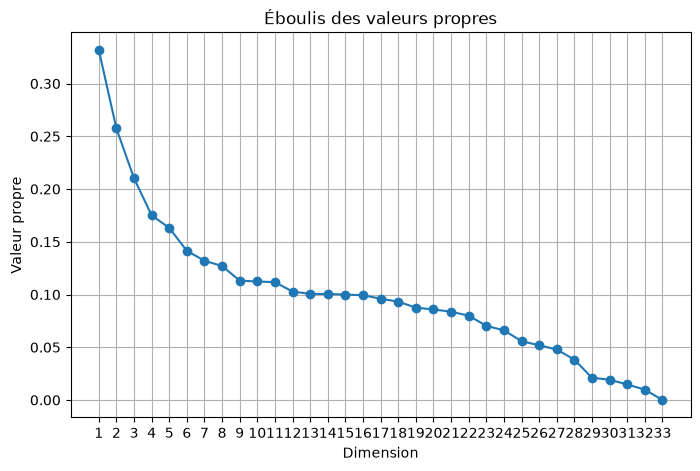

In [7]:
## Éboulis des valeurs propres

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(valeurs_propres) + 1),
    valeurs_propres,
    marker="o"
)

plt.xlabel("Dimension")
plt.ylabel("Valeur propre")
plt.title("Éboulis des valeurs propres")
plt.xticks(range(1, len(valeurs_propres) + 1))
plt.grid(True)

plt.show()

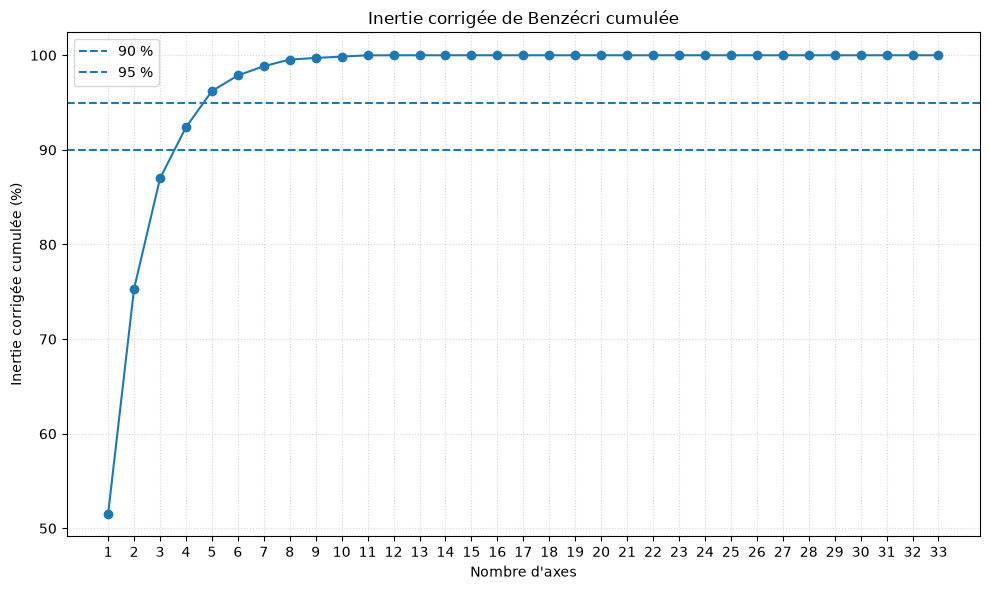

In [8]:
## Inertie corrigée de Benzécri cumulée

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(resultats_iteration_2["benzecri"]) + 1),
    np.cumsum(resultats_iteration_2["benzecri"]),
    marker='o'
)

plt.axhline(
    90,
    linestyle='--',
    label='90 %'
)

plt.axhline(
    95,
    linestyle='--',
    label='95 %'
)

plt.xlabel("Nombre d'axes")
plt.ylabel("Inertie corrigée cumulée (%)")
plt.title("Inertie corrigée de Benzécri cumulée")
plt.xticks(range(1, len(resultats_iteration_2["benzecri"]) + 1))
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

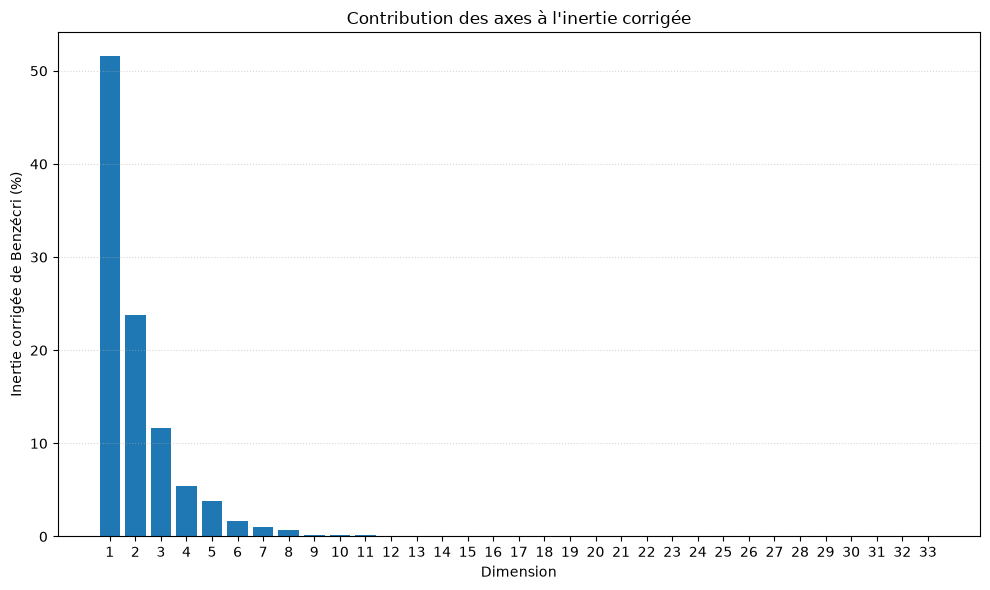

In [9]:
## Inertie corrigée de Benzécri par axe

plt.figure(figsize=(10, 6))

plt.bar(
    range(1, len(resultats_iteration_2["benzecri"]) + 1),
    resultats_iteration_2["benzecri"]
)

plt.xlabel("Dimension")
plt.ylabel("Inertie corrigée de Benzécri (%)")
plt.title("Contribution des axes à l'inertie corrigée")
plt.xticks(range(1, len(resultats_iteration_2["benzecri"]) + 1))
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
from src.classification_hierarchique import extraire_coordonnees
N_AXES_CAH = 4
coordonnees_individus = extraire_coordonnees(resultats_iteration_2, N_AXES_CAH)
print(f'Coordonnées pour la future CAH : {coordonnees_individus.shape}')

Coordonnées pour la future CAH : (68218, 4)


In [11]:
# Export des coordonnées factorielles pour la classification
coordonnees_factorielles = (
    resultats_iteration_2["modele"].row_coordinates(
        resultats_iteration_2["tableau_disjonctif"]
    )
)

chemin_sortie = RACINE / "resultats" / "coordonnees_factorielles.csv"
chemin_sortie.parent.mkdir(parents=True, exist_ok=True)

coordonnees_factorielles.to_csv(
    chemin_sortie,
    index=False
)

print(f"Coordonnées factorielles enregistrées : {chemin_sortie}")
print(f"Dimensions : {coordonnees_factorielles.shape}")

Coordonnées factorielles enregistrées : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\resultats\coordonnees_factorielles.csv
Dimensions : (68218, 33)
